# Task 2: Exploratory analysis

This notebook answers the three business questions, tests the five headline findings and selects ADR regression as the second prediction task. Statistical significance is described as association, not causation.


In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
SLIDE_DIR = Path('../slides')
MODEL_DIR = Path('../models')
for folder in [DATA_DIR, OUTPUT_DIR, SLIDE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

from scipy import stats


In [2]:
df = pd.read_csv(DATA_DIR / 'hotel_bookings_clean.csv', parse_dates=['arrival_date'])
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['year_month'] = df['arrival_date'].dt.to_period('M')
print('Rows:', len(df), 'Cancellation rate:', f"{df['is_canceled'].mean():.1%}")

def diff_prop_ci(success_a, n_a, success_b, n_b, z=1.96):
    p1, p2 = success_a / n_a, success_b / n_b
    diff = p1 - p2
    se = np.sqrt(p1*(1-p1)/n_a + p2*(1-p2)/n_b)
    return diff, diff-z*se, diff+z*se

findings = []


Rows: 119209 Cancellation rate: 37.1%


## Q1: Cancellation risk

Cancellation includes both records marked `Canceled` and `No-Show` in the source target.


               mean   size
hotel                     
City Hotel    0.418  79163
Resort Hotel  0.278  40046
               mean    size
deposit_type               
Non Refund    0.994   14587
No Deposit    0.284  104460
Refundable    0.222     162
                 mean   size
lead_time_band              
0-7             0.096  19635
8-30            0.279  18945
31-90           0.377  29529
91-180          0.447  26420
181+            0.570  24680


               mean   size
hotel                     
City Hotel    0.418  79163
Resort Hotel  0.278  40046

               mean    size
deposit_type               
Non Refund    0.994   14587
No Deposit    0.284  104460
Refundable    0.222     162

                 mean   size
lead_time_band              
0-7             0.096  19635
8-30            0.279  18945
31-90           0.377  29529
91-180          0.447  26420
181+            0.570  24680

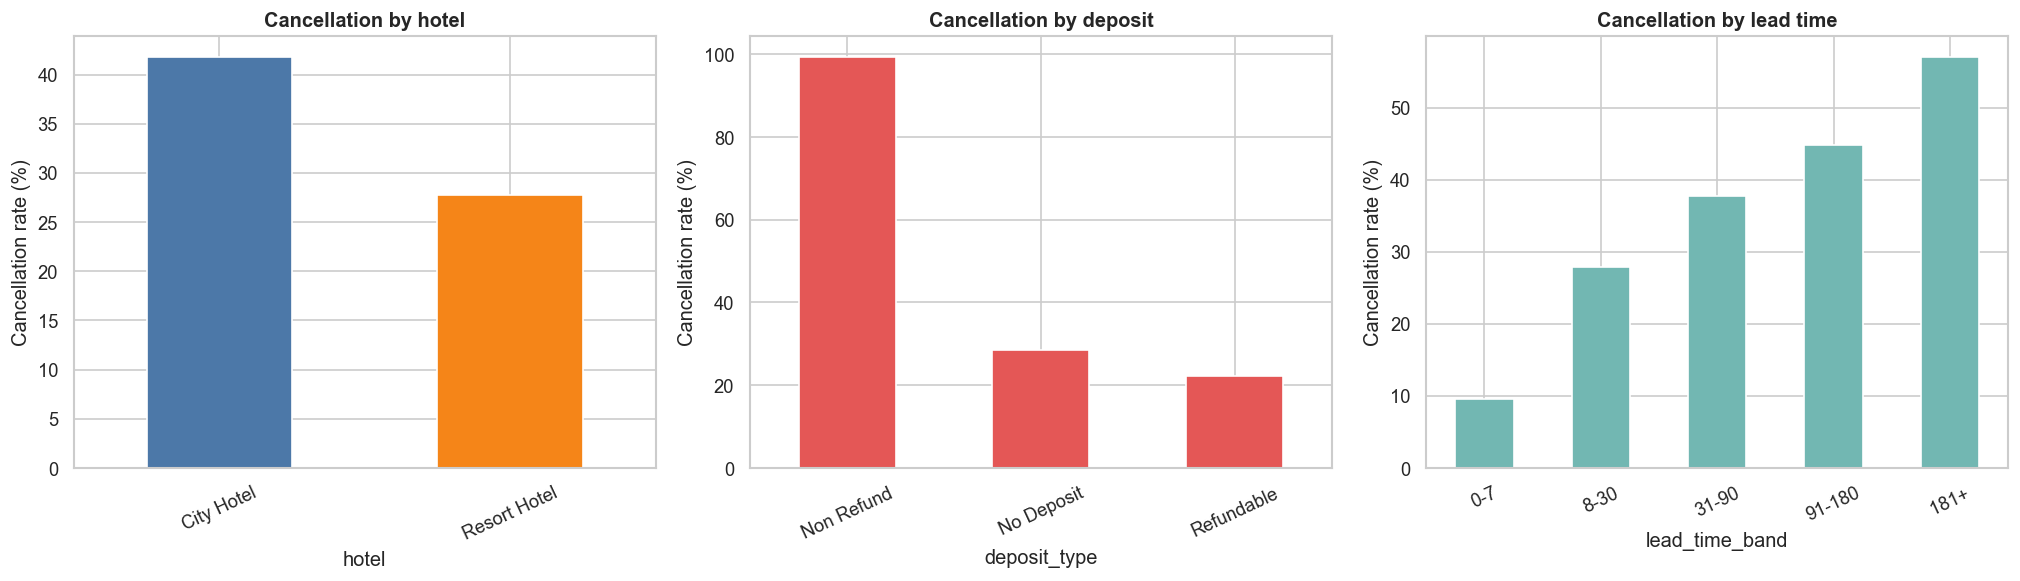

In [3]:
lead_bins = [-1, 7, 30, 90, 180, np.inf]
lead_labels = ['0-7', '8-30', '31-90', '91-180', '181+']
df['lead_time_band'] = pd.cut(df['lead_time'], lead_bins, labels=lead_labels)

by_hotel = df.groupby('hotel')['is_canceled'].agg(['mean','size']).sort_values('mean', ascending=False)
by_deposit = df.groupby('deposit_type')['is_canceled'].agg(['mean','size']).sort_values('mean', ascending=False)
by_lead = df.groupby('lead_time_band', observed=True)['is_canceled'].agg(['mean','size'])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
by_hotel['mean'].mul(100).plot.bar(ax=axes[0], color=['#4C78A8','#F58518'])
by_deposit['mean'].mul(100).plot.bar(ax=axes[1], color='#E45756')
by_lead['mean'].mul(100).plot.bar(ax=axes[2], color='#72B7B2')
for ax, title in zip(axes, ['Cancellation by hotel','Cancellation by deposit','Cancellation by lead time']):
    ax.set_title(title, fontweight='bold'); ax.set_ylabel('Cancellation rate (%)'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'eda_cancellation.png', bbox_inches='tight'); plt.show()
display(by_hotel.round(3)); display(by_deposit.round(3)); display(by_lead.round(3))


## Q2: Expected ADR

ADR is the quoted average nightly lodging rate. The model in Task 6 predicts this value using information known at booking time.


count    119208.000000
mean        101.925557
std          48.042334
min           0.000000
25%          69.500000
50%          94.950000
75%         126.000000
95%         193.500000
99%         252.000000
max         510.000000
Name: adr, dtype: float64


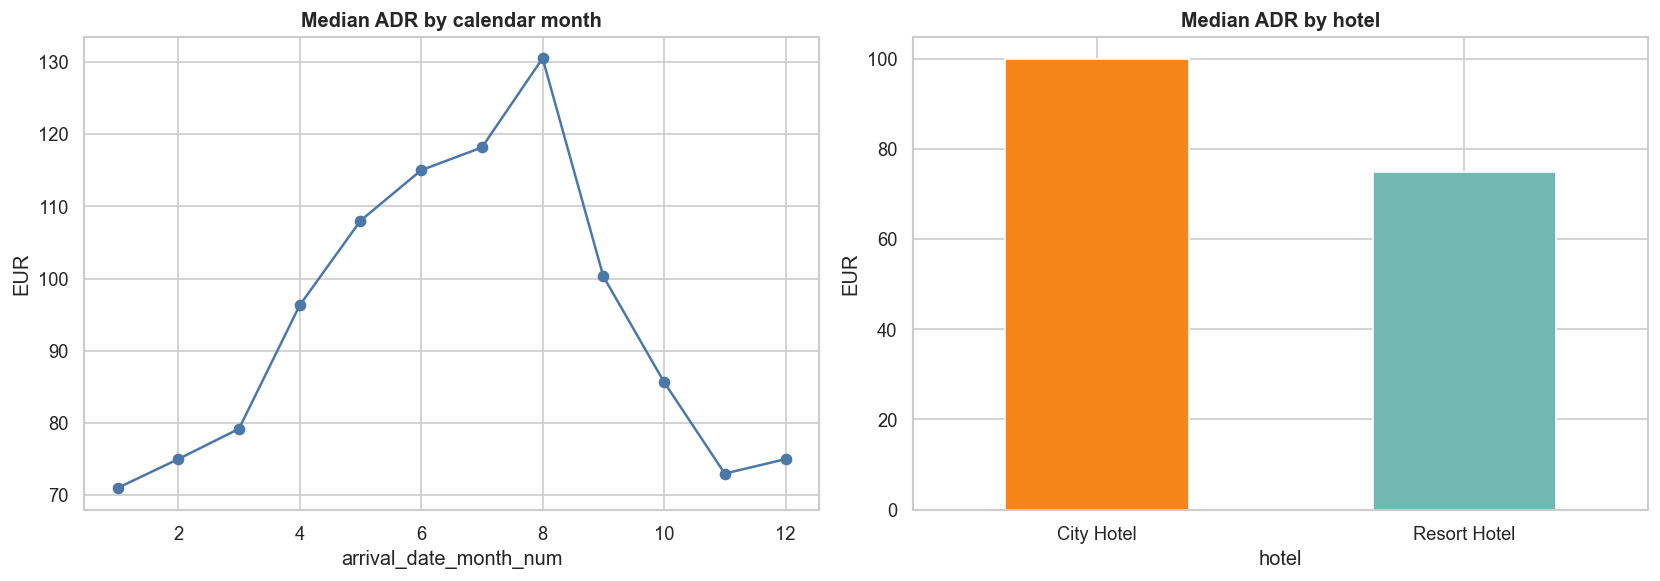

In [4]:
valid_adr = df.loc[df['adr_extreme_flag'].eq(0) & df['adr'].ge(0)].copy()
adr_month = valid_adr.groupby('arrival_date_month_num')['adr'].median()
adr_hotel = valid_adr.groupby('hotel')['adr'].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
adr_month.plot(ax=axes[0], marker='o', color='#4C78A8')
adr_hotel.plot.bar(ax=axes[1], color=['#F58518','#72B7B2'])
axes[0].set_title('Median ADR by calendar month', fontweight='bold'); axes[0].set_ylabel('EUR')
axes[1].set_title('Median ADR by hotel', fontweight='bold'); axes[1].set_ylabel('EUR'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'eda_adr.png', bbox_inches='tight'); plt.show()
print(valid_adr['adr'].describe(percentiles=[.25,.5,.75,.95,.99]))


## Q3: Recorded demand

The source lacks room capacity. The charts therefore show completed nights and average monthly demand, not occupancy.


       avg_completed_bookings  avg_nights_sold  observed_months
month                                                          
1                      2057.5           5631.0                2
2                      2679.5           7871.5                2
3                      3309.5          10828.0                2
4                      3280.0          10882.0                2
5                      3551.5          11795.5                2
6                      3197.5          11560.0                2
7                      2635.7          10287.3                3
8                      2874.7          11220.3                3
9                      3192.5          11435.0                2
10                     3450.5          10886.0                2
11                     2325.5           7344.5                2
12                     2195.5           6646.0                2


       avg_completed_bookings  avg_nights_sold  observed_months
month                                                          
1                      2057.5           5631.0                2
2                      2679.5           7871.5                2
3                      3309.5          10828.0                2
4                      3280.0          10882.0                2
5                      3551.5          11795.5                2
6                      3197.5          11560.0                2
7                      2635.7          10287.3                3
8                      2874.7          11220.3                3
9                      3192.5          11435.0                2
10                     3450.5          10886.0                2
11                     2325.5           7344.5                2
12                     2195.5           6646.0                2

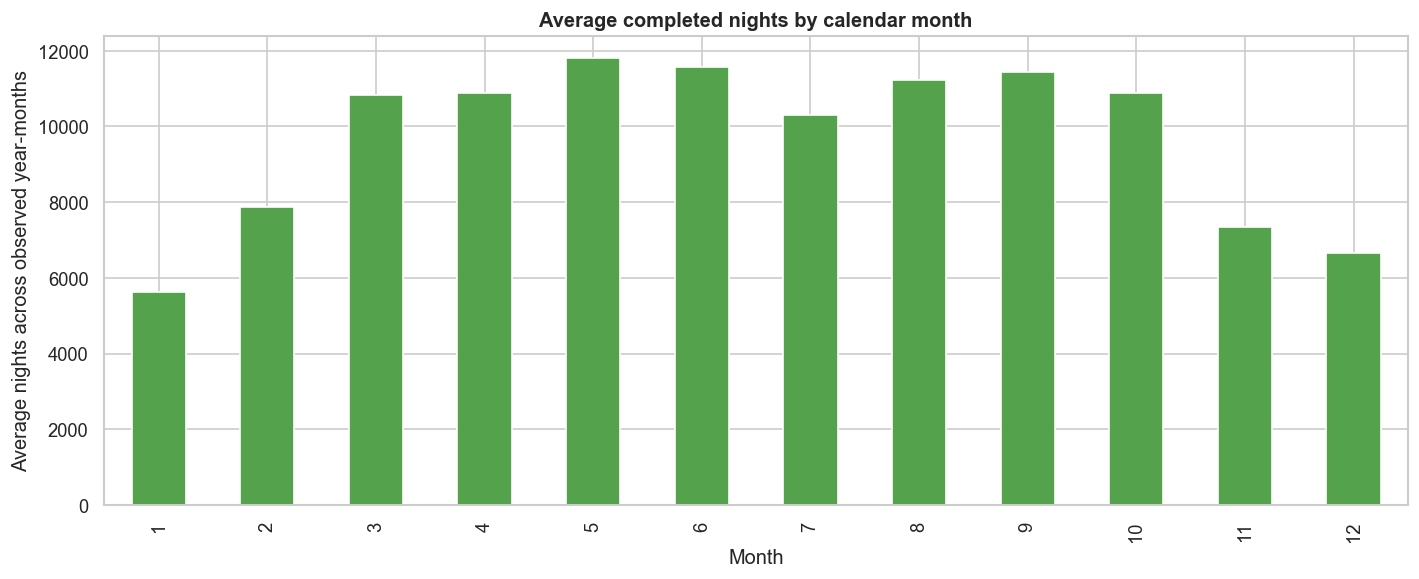

In [5]:
completed = df[df['reservation_status'].eq('Check-Out')].copy()
monthly_demand = completed.groupby('year_month').agg(
    completed_bookings=('source_row_id','size'),
    nights_sold=('total_nights','sum'),
    weighted_adr_num=('adr', lambda x: 0.0),
).drop(columns='weighted_adr_num')
calendar_month = monthly_demand.assign(month=monthly_demand.index.month).groupby('month').agg(
    avg_completed_bookings=('completed_bookings','mean'),
    avg_nights_sold=('nights_sold','mean'),
    observed_months=('completed_bookings','size'),
)
fig, ax = plt.subplots(figsize=(12, 5))
calendar_month['avg_nights_sold'].plot.bar(ax=ax, color='#54A24B')
ax.set_title('Average completed nights by calendar month', fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Average nights across observed year-months')
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'eda_demand.png', bbox_inches='tight'); plt.show()
display(calendar_month.round(1))


## Five tested business findings

Each finding includes a number, a statistical check and a practical action. Large samples can make small differences statistically significant, so the effect size and population remain visible.


                    finding  ...                                             action
0       No special requests  ...  Send reminders to high-risk bookings; test the...
1   Non-refundable bookings  ...  Audit channel and contract rules before changi...
2                Summer ADR  ...  Use seasonal pricing controls and validate by ...
3   City Hotel cancellation  ...          Set hotel-specific monitoring thresholds.
4  Lead time above 180 days  ...  Prioritize early-booked reservations for confi...

[5 rows x 8 columns]


                    finding  ...                                             action
0       No special requests  ...  Send reminders to high-risk bookings; test the...
1   Non-refundable bookings  ...  Audit channel and contract rules before changi...
2                Summer ADR  ...  Use seasonal pricing controls and validate by ...
3   City Hotel cancellation  ...          Set hotel-specific monitoring thresholds.
4  Lead time above 180 days  ...  Prioritize early-booked reservations for confi...

[5 rows x 8 columns]

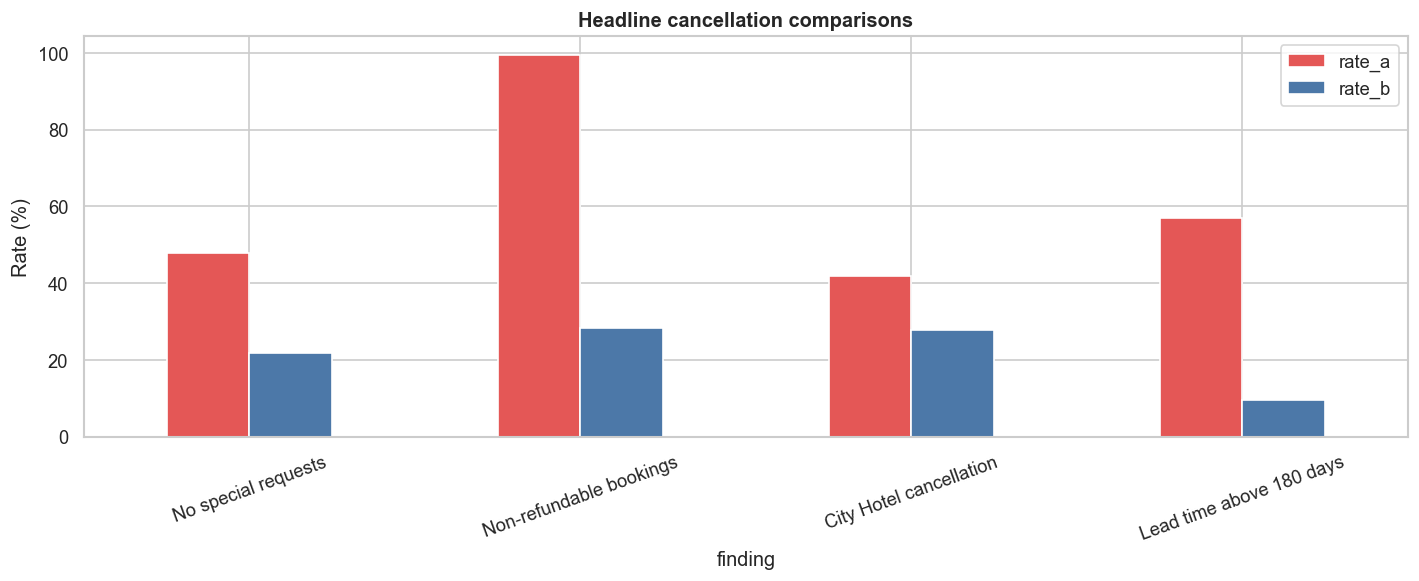

In [6]:
# Finding 1: special requests
a = df[df['total_of_special_requests'].eq(0)]['is_canceled']
b = df[df['total_of_special_requests'].gt(0)]['is_canceled']
ct = pd.crosstab(df['total_of_special_requests'].gt(0), df['is_canceled'])
chi2, p1, _, _ = stats.chi2_contingency(ct)
d1, lo1, hi1 = diff_prop_ci(a.sum(), len(a), b.sum(), len(b))
findings.append({'finding':'No special requests','rate_a':a.mean(),'rate_b':b.mean(),'difference':d1,'ci_low':lo1,'ci_high':hi1,'p_value':p1,'action':'Send reminders to high-risk bookings; test the intervention before requiring deposits.'})

# Finding 2: non-refundable deposit
nr = df[df['deposit_type'].eq('Non Refund')]['is_canceled']
nd = df[df['deposit_type'].eq('No Deposit')]['is_canceled']
deposit_compare = df[df['deposit_type'].isin(['Non Refund','No Deposit'])]
ct = pd.crosstab(deposit_compare['deposit_type'], deposit_compare['is_canceled'])
chi2, p2, _, _ = stats.chi2_contingency(ct)
d2, lo2, hi2 = diff_prop_ci(nr.sum(), len(nr), nd.sum(), len(nd))
findings.append({'finding':'Non-refundable bookings','rate_a':nr.mean(),'rate_b':nd.mean(),'difference':d2,'ci_low':lo2,'ci_high':hi2,'p_value':p2,'action':'Audit channel and contract rules before changing the deposit policy.'})

# Finding 3: summer ADR
summer = valid_adr[valid_adr['arrival_date_month_num'].isin([6,7,8])]['adr']
winter = valid_adr[valid_adr['arrival_date_month_num'].isin([12,1,2])]['adr']
stat3, p3 = stats.mannwhitneyu(summer, winter, alternative='two-sided')
findings.append({'finding':'Summer ADR','rate_a':summer.median(),'rate_b':winter.median(),'difference':summer.median()-winter.median(),'ci_low':np.nan,'ci_high':np.nan,'p_value':p3,'action':'Use seasonal pricing controls and validate by hotel.'})

# Finding 4: city versus resort cancellation
city = df[df['hotel'].eq('City Hotel')]['is_canceled']
resort = df[df['hotel'].eq('Resort Hotel')]['is_canceled']
ct = pd.crosstab(df['hotel'], df['is_canceled'])
chi2, p4, _, _ = stats.chi2_contingency(ct)
d4, lo4, hi4 = diff_prop_ci(city.sum(), len(city), resort.sum(), len(resort))
findings.append({'finding':'City Hotel cancellation','rate_a':city.mean(),'rate_b':resort.mean(),'difference':d4,'ci_low':lo4,'ci_high':hi4,'p_value':p4,'action':'Set hotel-specific monitoring thresholds.'})

# Finding 5: long lead time
short = df[df['lead_time'].le(7)]['is_canceled']
long = df[df['lead_time'].gt(180)]['is_canceled']
ct = pd.crosstab(df['lead_time'].gt(180), df['is_canceled'])
chi2, p5, _, _ = stats.chi2_contingency(ct)
d5, lo5, hi5 = diff_prop_ci(long.sum(), len(long), short.sum(), len(short))
findings.append({'finding':'Lead time above 180 days','rate_a':long.mean(),'rate_b':short.mean(),'difference':d5,'ci_low':lo5,'ci_high':hi5,'p_value':p5,'action':'Prioritize early-booked reservations for confirmation reminders.'})

findings_df = pd.DataFrame(findings)
display(findings_df)
findings_df.to_csv(OUTPUT_DIR / 'eda_findings.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 5))
plot = findings_df.drop(index=2).set_index('finding')[['rate_a','rate_b']].mul(100)
plot.plot.bar(ax=ax, color=['#E45756','#4C78A8'])
ax.set_title('Headline cancellation comparisons', fontweight='bold'); ax.set_ylabel('Rate (%)'); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'eda_five_findings.png', bbox_inches='tight'); plt.show()


## Non-Refund investigation and second prediction

The Non-Refund pattern remains an association. Segment counts and cancellation rates must both be considered before changing a contract or deposit policy.


In [7]:
non_refund = df[df['deposit_type'].eq('Non Refund')]
nr_segments = non_refund.groupby('market_segment').agg(
    bookings=('source_row_id','size'),
    cancellation_rate=('is_canceled','mean'),
    median_lead_time=('lead_time','median'),
    median_adr=('adr','median'),
).sort_values('bookings', ascending=False)
display(nr_segments)
nr_segments.to_csv(OUTPUT_DIR / 'non_refund_investigation.csv')

print('Second prediction: ADR regression')
print('Audience: revenue management')
print('Use: compare the quoted ADR with the model expectation and review materially underpriced bookings.')


                bookings  cancellation_rate  median_lead_time  median_adr
market_segment                                                           
Groups              9172           0.993240             213.0        75.0
Offline TA/TO       5006           0.999401             177.0        95.0
Corporate            334           0.934132              38.0        90.0
Online TA             56           0.946429               7.0        85.5
Direct                19           0.842105             163.0       100.0
Second prediction: ADR regression
Audience: revenue management
Use: compare the quoted ADR with the model expectation and review materially underpriced bookings.


                bookings  cancellation_rate  median_lead_time  median_adr
market_segment                                                           
Groups              9172           0.993240             213.0        75.0
Offline TA/TO       5006           0.999401             177.0        95.0
Corporate            334           0.934132              38.0        90.0
Online TA             56           0.946429               7.0        85.5
Direct                19           0.842105             163.0       100.0